In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import classification_report, silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neighbors import NearestNeighbors

In [2]:
rand = 42
sample_amount = 40_000
feature_amount = 20
blob_amount = 8
cluster_std = 1.2

X, _ = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=blob_amount, cluster_std=cluster_std, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [41]:
def inject_noise(df, noise_frac, seed, n_features_affected=None):

    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    mask = np.zeros(n, dtype=int)
    for row_id in noise_idx:
        method = rng.integers(low=1, high=5, endpoint=True)
        mask[row_id] = method
        match (method):
            case 1:
                cols = rng.choice(cols_all, size=1, replace=False)
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(8, 12) * std

            case 2:
                cols = rng.choice(cols_all, size=n_features_affected, replace=False)
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(4, 6) * std

            case 3:
                wide_n = min(int(n_features_affected * 2.0), int(len(cols_all) * 0.5))
                cols = rng.choice(cols_all, size=wide_n, replace=False)
                donor_row = rng.choice(df.index[df.index != row_id])
                for col in cols:
                    noisy.loc[row_id, col] = df.loc[donor_row, col]

            case 4:
                wide_n = max(3, n_features_affected - 1)
                cols = rng.choice(cols_all, size=wide_n, replace=False)
                for col in cols:
                    donor_row = rng.choice(df.index[df.index != row_id])
                    noisy.loc[row_id, col] = df.loc[donor_row, col]

            case 5:
                narrow_n = max(3, int(n_features_affected * 0.8))
                cols = rng.choice(cols_all, size=narrow_n, replace=False)
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(0.5, 0.85) * std

    return noisy, pd.Series(mask, index=df.index)

contam=0.1

noisy_df, true_mask = inject_noise(df, noise_frac=contam, n_features_affected=5, seed=rand)

In [ ]:
#AMOUNT OF NOISE
print(len(np.array(np.where(true_mask == True)).reshape(-1))/len(true_mask))

In [ ]:
rand = 42

gt_2015 = pd.read_csv("gt_2015.csv")
gt_2014 = pd.read_csv("gt_2014.csv")
gt_2013 = pd.read_csv("gt_2013.csv")
gt_2012 = pd.read_csv("gt_2012.csv")
gt_2011 = pd.read_csv("gt_2011.csv")
noisy_df = pd.concat([gt_2015, gt_2014, gt_2013, gt_2012, gt_2011])

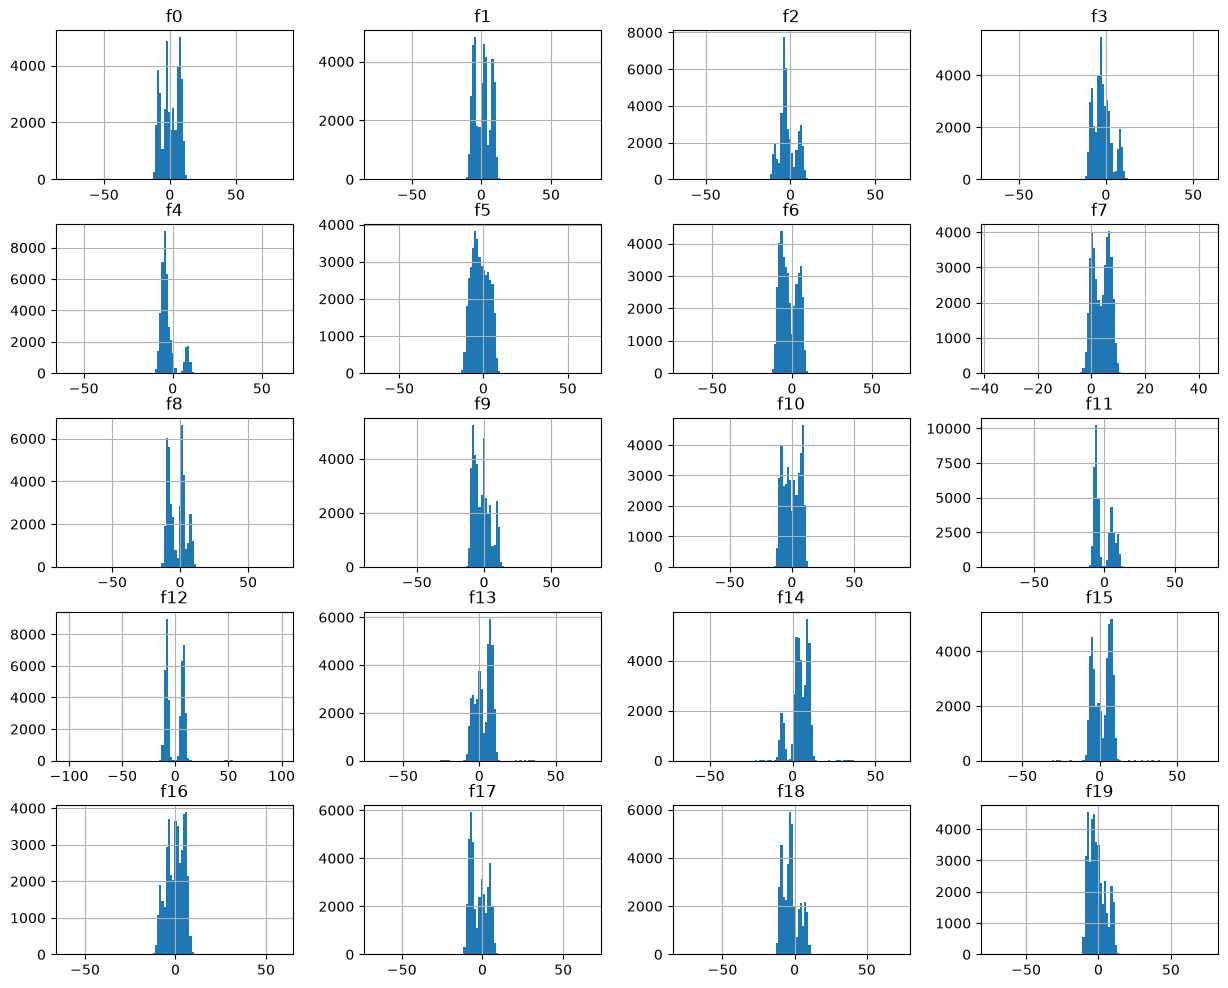

In [47]:
#HIST OF ALL FEATURES
noisy_df.hist(figsize=(15, 12), bins=100)
plt.show()

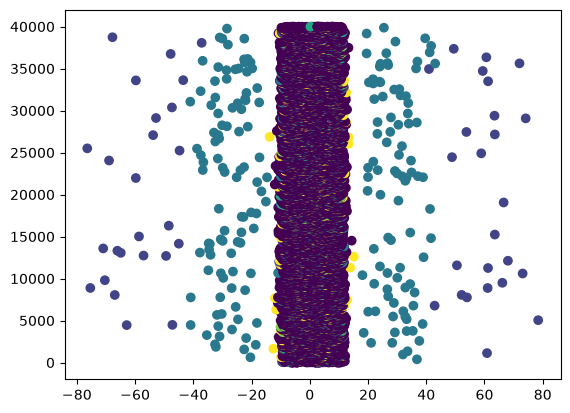

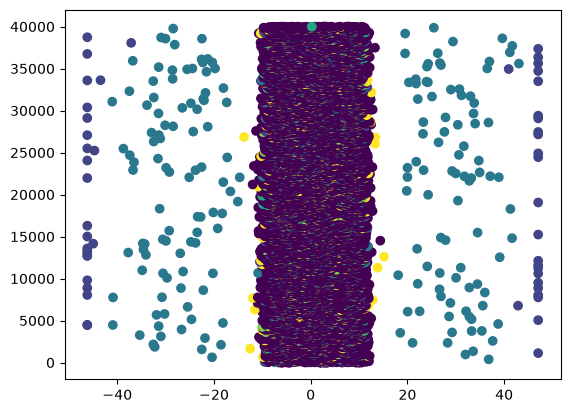

In [54]:
#PLOT FIRST FEATURE
plt.scatter(noisy_df.iloc[:, 1], df.index, c=true_mask)
plt.show()

plt.scatter(clean_df.iloc[:, 1], df.index, c=true_mask)
plt.show()

In [ ]:
def remove_print(data, flagged, mask=None):
    if mask is not None:
        fp = n1 = n2 = n3 = n4 = n5 = 0
        for i in range(len(mask)):
            if flagged[i] == True:
                match mask[i]:
                    case 0:
                        fp += 1
                    case 1:
                        n1 += 1
                    case 2:
                        n2 += 1
                    case 3:
                        n3 += 1
                    case 4:
                        n4 += 1
                    case 5:
                        n5 += 1
        print(f"false positives: {fp}")
        print(f"true positives: {n1 + n2 + n3 + n4 + n5}\n")
        print(f"noise 1 detected {n1}")
        print(f"noise 2 detected {n2}")
        print(f"noise 3 detected {n3}")
        print(f"noise 4 detected {n4}")
        print(f"noise 5 detected {n5}\n")
        #currently judging on all noise, instead judge on own noise
        print(classification_report(mask != 0, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
        keep = ~flagged
        data = data.loc[keep]
        print(f"entries remaining: {len(data)}")
        print(f"\n=============================================")
        print(f"=============================================")
        print(f"=============================================\n")
        mask = mask[keep]
        return data, mask
    else:
        keep = ~flagged
        data = data.loc[keep]
        print(f"entries removed: {len(keep) - len(data)}")
        print(f"entries remaining: {len(data)}")
        print(f"\n=============================================")
        print(f"=============================================")
        print(f"=============================================\n")
        return data

def run_iqr(data, iqr_fence, iqr_col_ratio, mask=None):
    suspects = np.zeros(len(data), dtype=int)
    for col in data.columns:
        Q1 = np.percentile(data[col], 25)
        Q3 = np.percentile(data[col], 75)
        IQR = Q3 - Q1
        lower, upper = Q1 - iqr_fence * IQR, Q3 + iqr_fence * IQR
        suspects += (data[col] < lower) | (data[col] > upper)
    flagged = (suspects > len(data.columns) * iqr_col_ratio).to_numpy()
    print(f"IQR: ")
    return remove_print(data=data, flagged=flagged, mask=mask)

def run_isolation_forest(data, isof_estimators, mask=None):
    model = IsolationForest(n_estimators=isof_estimators, contamination='auto', n_jobs=-1, random_state=rand)
    flagged = model.fit_predict(data) == -1
    print(f"ISOLATION FOREST: ")
    return remove_print(data=data, flagged=flagged, mask=mask)

def run_kmeans(data, kmeans_init, kmeans_contam, mask=None, kmeans_clusters=None):
    scaled = StandardScaler().fit_transform(data)
    if kmeans_clusters is None:
        kmeans_clusters = 2
        best = 0
        while True:
            k_means = KMeans(n_clusters=kmeans_clusters, random_state=rand, init="k-means++", n_init=20)
            predicted_labels = k_means.fit_predict(data)
            silhouette = silhouette_score(data, predicted_labels)
            if silhouette < best:
                print(f"kmeans cluster amount found: {kmeans_clusters}")
                break
            else:
                kmeans_clusters += 1
                best = silhouette
    kmeans = KMeans(n_clusters=kmeans_clusters, random_state=rand, n_init=kmeans_init, init="k-means++")
    kmeans.fit(scaled)
    distances = np.min(kmeans.transform(scaled), axis=1)
    threshold = np.percentile(distances, (1 - kmeans_contam) * 100)
    flagged = distances > threshold
    print(f"K MEANS: ")
    return remove_print(data=data, flagged=flagged, mask=mask)  

def run_dbscan(data, dbscan_eps, dbscan_min_samp, mask=None):
    scaled = StandardScaler().fit_transform(data)
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samp, n_jobs=-1)
    flagged = dbscan.fit_predict(scaled) == -1
    print(f"DBSCAN: ")
    return remove_print(data=data, flagged=flagged, mask=mask)

def run_lof(data, lof_neighbors, mask=None):
    scaled = StandardScaler().fit_transform(data)
    lof = LocalOutlierFactor(n_neighbors=lof_neighbors, contamination='auto')
    flagged = lof.fit_predict(scaled) == -1
    print(f"LOF: ")
    return remove_print(data=data, flagged=flagged, mask=mask)

def pipeline(data, mask=None, clusters=None, contam=None):
    #hyperparam
    iqr_fence = 1.5
    iqr_col_ratio = 0.8
    isof_estimators = 480 
    kmeans_init = 20
    if contam is not None:
        kmeans_contam = contam / 5
    else:
        kmeans_contam = 0.02
    dbscan_eps = 1.5
    dbscan_min_samp = 20
    lof_neighbors = 20

    if mask is None:
        data = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio)
        data = run_isolation_forest(data=data, isof_estimators=isof_estimators)
        data = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam)
        data = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp)
        data = run_lof(data=data, lof_neighbors=lof_neighbors)
        return data
    else:
        data, mask = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio, mask=mask)
        data, mask = run_isolation_forest(data=data, isof_estimators=isof_estimators, mask=mask)
        data, mask = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam, mask=mask)
        data, mask = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp, mask=mask)
        data, mask = run_lof(data=data, lof_neighbors=lof_neighbors, mask=mask)
        return data, mask

In [ ]:
def impute_flagged_knn(data, flagged, knn_neighbors = 5):
    data = data.copy()
    clean = data.loc[~flagged]
    if flagged.sum() == 0 or len(clean) <= knn_neighbors:
        return data
    scaler = StandardScaler().fit(clean)
    nn = NearestNeighbors(n_neighbors=knn_neighbors).fit(scaler.transform(clean))
    _, idx = nn.kneighbors(scaler.transform(data.loc[flagged]))
    clean_vals = clean.to_numpy()
    imputed = clean_vals[idx].mean(axis=1)
    data.loc[flagged, :] = imputed
    return data

#NB metrics!

def mitigate_print(data, flagged, mask=None, mitigation=1,
                    bounds=None, knn_neighbors=5):
    flagged = np.asarray(flagged)
    print(f"flagged: {flagged.sum()} / {len(flagged)}")

    match(mitigation):
        case 1: #remove
            keep = ~flagged
            data = data.loc[keep]
            if mask is not None:
                mask = mask.loc[keep]

        case 2: #impute
            fixed_index = data.index[flagged]
            data = impute_flagged_knn(data, flagged, knn_neighbors=knn_neighbors)
            if mask is not None:
                mask = mask.copy()
                mask.loc[fixed_index] = 0

    print(f"entries remaining: {len(data)}")
    print("=" * 45, "\n")

    if mask is not None:
        return data, mask
    return data

#NB fix IQR

def run_iqr(data, iqr_fence, mask=None):
    for col in data.columns:
        original = df[col].copy()
        Q1 = np.percentile(data[col], 25)
        Q3 = np.percentile(data[col], 75)
        IQR = Q3 - Q1
        lower, upper = Q1 - iqr_fence * IQR, Q3 + iqr_fence * IQR
        data[col] = data[col].clip(lower=lower, upper=upper)
        affected_count = (original != data[col]).sum()
        print(affected_count)
    if mask is not None:
        return data, mask
    return data

'''
def run_iqr(data, iqr_fence, iqr_col_ratio, mask=None, mitigation=2):
    suspects = np.zeros(len(data), dtype=int)
    bounds = {}
    for col in data.columns:
        Q1 = np.percentile(data[col], 25)
        Q3 = np.percentile(data[col], 75)
        IQR = Q3 - Q1
        lower, upper = Q1 - iqr_fence * IQR, Q3 + iqr_fence * IQR
        bounds[col] = (lower, upper)
        suspects += ((data[col] < lower) | (data[col] > upper)).to_numpy()
    flagged = suspects > len(data.columns) * iqr_col_ratio
    return mitigate_print(data=data, flagged=flagged, mask=mask,
                           mitigation=mitigation, bounds=bounds)

def winsorize_flagged(data, flagged, bounds):
    data = data.copy()
    for col, (lower, upper) in bounds.items():
        data.loc[flagged, col] = data.loc[flagged, col].clip(lower, upper)
    return data
'''

def run_isolation_forest(data, isof_estimators, mask=None, mitigation=1):
    model = IsolationForest(n_estimators=isof_estimators, contamination='auto', n_jobs=-1, random_state=rand)
    flagged = model.fit_predict(data) == -1
    return mitigate_print(data=data, flagged=flagged, mask=mask,
                           mitigation=mitigation)


def run_kmeans(data, kmeans_init, kmeans_contam, mask=None, kmeans_clusters=None,
               mitigation=2, knn_neighbors=5):
    scaled = StandardScaler().fit_transform(data)
    if kmeans_clusters is None:
        kmeans_clusters = 2
        best = 0
        while True:
            k_means = KMeans(n_clusters=kmeans_clusters, random_state=rand, init="k-means++", n_init=20)
            predicted_labels = k_means.fit_predict(data)
            silhouette = silhouette_score(data, predicted_labels)
            if silhouette < best:
                print(f"kmeans cluster amount found: {kmeans_clusters}")
                break
            else:
                kmeans_clusters += 1
                best = silhouette
    kmeans = KMeans(n_clusters=kmeans_clusters, random_state=rand, n_init=kmeans_init, init="k-means++")
    kmeans.fit(scaled)
    distances = np.min(kmeans.transform(scaled), axis=1)
    threshold = np.percentile(distances, (1 - kmeans_contam) * 100)
    flagged = distances > threshold
    return mitigate_print(data=data, flagged=flagged, mask=mask,
                           mitigation=mitigation, knn_neighbors=knn_neighbors)


def run_dbscan(data, dbscan_eps, dbscan_min_samp, mask=None, mitigation=2, knn_neighbors=5):
    scaled = StandardScaler().fit_transform(data)
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samp, n_jobs=-1)
    flagged = dbscan.fit_predict(scaled) == -1
    return mitigate_print(data=data, flagged=flagged, mask=mask,
                           mitigation=mitigation, knn_neighbors=knn_neighbors)


def run_lof(data, lof_neighbors, mask=None, mitigation=2, knn_neighbors=5):
    scaled = StandardScaler().fit_transform(data)
    lof = LocalOutlierFactor(n_neighbors=lof_neighbors, contamination='auto')
    flagged = lof.fit_predict(scaled) == -1
    return mitigate_print(data=data, flagged=flagged, mask=mask,
                           mitigation=mitigation, knn_neighbors=knn_neighbors)


def pipeline(data, mask=None, clusters=None, contam=None):
    iqr_fence = 1.5
    isof_estimators = 480
    kmeans_init = 20
    kmeans_contam = contam / 5 if contam is not None else 0.02
    dbscan_eps = 1.5
    dbscan_min_samp = 20
    lof_neighbors = 20
    knn_neighbors = 5

    if mask is None:
        data = run_iqr(data=data, iqr_fence=iqr_fence)
        data = run_isolation_forest(data=data, isof_estimators=isof_estimators)
        data = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam, knn_neighbors=knn_neighbors)
        data = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp, knn_neighbors=knn_neighbors)
        data = run_lof(data=data, lof_neighbors=lof_neighbors, knn_neighbors=knn_neighbors)
        return data

    data, mask = run_iqr(data=data, iqr_fence=iqr_fence, mask=mask)
    data, mask = run_isolation_forest(data=data, isof_estimators=isof_estimators, mask=mask)
    data, mask = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam, mask=mask, knn_neighbors=knn_neighbors)
    data, mask = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp, mask=mask, knn_neighbors=knn_neighbors)
    data, mask = run_lof(data=data, lof_neighbors=lof_neighbors, mask=mask, knn_neighbors=knn_neighbors)

    #NB add final metrics over all noise here

    return data, mask

In [16]:
data = noisy_df.copy()
clean_df = pipeline(data, contam=0)

flagged: 774 / 40000
entries remaining: 40000

flagged: 1621 / 40000
entries remaining: 38379

kmeans cluster amount found: 10
flagged: 0 / 38379
entries remaining: 38379

flagged: 1346 / 38379
entries remaining: 38379

flagged: 607 / 38379
entries remaining: 38379



In [51]:
iqr_fence = 4
data = noisy_df.copy()
clean_df = run_iqr(data=data, iqr_fence=iqr_fence)

952
930
953
934
972
942
953
1008
946
975
981
903
972
929
1009
921
966
982
970
1008


In [ ]:
data = noisy_df.copy()
mask = true_mask.copy()
clean_df, mask = pipeline(data, mask, contam=contam, clusters=10)

NameError: name 'iqr_fence' is not defined

In [17]:
def end_kmeans(data, clusters):
    normalized_data = data.copy()
    scaler = MinMaxScaler()
    normalized_data[normalized_data.columns] = scaler.fit_transform(normalized_data)
    kmeans = KMeans(n_clusters=clusters, n_init='auto')
    kmeans_pred = kmeans.fit_predict(normalized_data)
    return kmeans_pred, normalized_data

n_pred, n_norm = end_kmeans(noisy_df, 8)############################################amount of clusters
c_pred, c_norm = end_kmeans(clean_df, 8)############################################amount of clusters

In [18]:
n_ss = silhouette_score(n_norm, n_pred)
c_ss = silhouette_score(c_norm, c_pred)

n_dbi = davies_bouldin_score(n_norm, n_pred)
c_dbi = davies_bouldin_score(c_norm, c_pred)

n_chi = calinski_harabasz_score(n_norm, n_pred)
c_chi = calinski_harabasz_score(c_norm, c_pred)

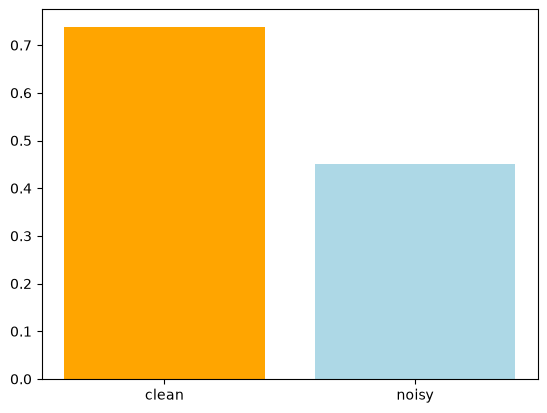

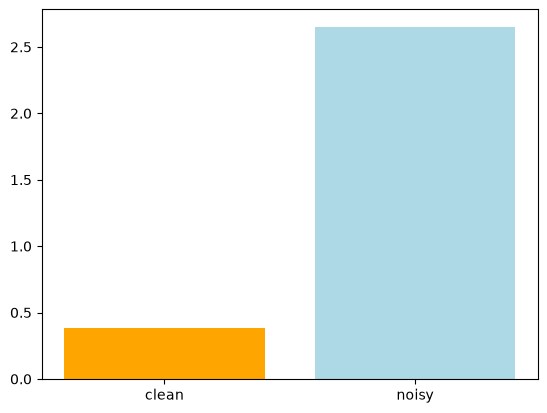

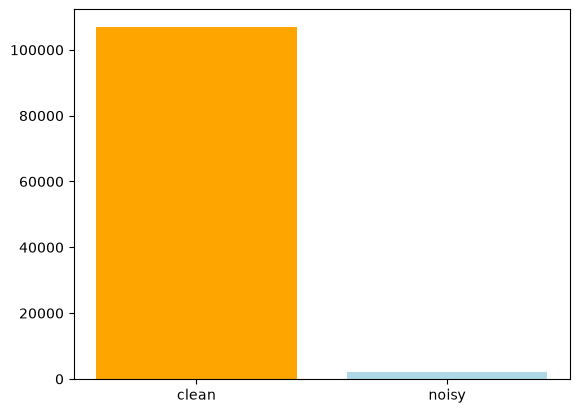

In [19]:
plt.bar(['clean', 'noisy'], [c_ss, n_ss], color=['orange', 'lightblue'])
plt.show()

plt.bar(['clean', 'noisy'], [c_dbi, n_dbi], color=['orange', 'lightblue'])
plt.show()

plt.bar(['clean', 'noisy'], [c_chi, n_chi], color=['orange', 'lightblue'])
plt.show()